In [15]:
# 그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error  # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler # 정규화클래스
from sklearn.model_selection import train_test_split

In [10]:
# 데이터전처리
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0, 
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5, 
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5, 
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0, 
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0, 
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0, 
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0, 
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0, 
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0, 
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0, 
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0, 
    1000.0, 1000.0]
    )

In [11]:
# 학습데이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = train_test_split(perch_length,perch_weight)

In [12]:
train_data

array([44. , 43. , 22. , 40. , 27.5, 30. , 28. , 23.5, 43. , 18. , 22. ,
       37. , 18.7, 37. , 26.5, 25. , 23. , 22. , 21.3, 27.5, 22.7, 22.5,
       21. , 24. , 25.6, 35. , 22. , 43.5, 40. , 36. , 19. , 39. , 21. ,
       22.5, 24.6, 19.6, 32.8,  8.4, 34.5, 22. , 36.5, 39. ])

In [18]:
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
test_data[:3]

array([[40. ],
       [20. ],
       [13.7]])

In [14]:
# 데이터 학습
# clf = KNeighborsClassifier()
knr = KNeighborsRegressor()
knr.fit(train_data,train_label)
# 데이터 예측
predict = knr.predict(test_data)
print("예측무게 : ",predict)

# 정확도,오차
score = knr.score(train_data,train_label)
score2 = knr.score(test_data,test_label)
print('정확도1 : ',score)
print('정확도2 : ',score2)


예측무게 :  [ 838.    104.     69.78  235.     91.6    91.6   778.    259.6   235.
  182.6   119.   1000.    838.     91.6 ]
정확도1 :  0.9821615909483289
정확도2 :  0.9659340821806979


In [16]:
# 오차범위
mae = mean_absolute_error(test_label,predict)
print("오차범위(g) : ",mae)

오차범위(g) :  54.29142857142857


예측무게 :  [1000.]


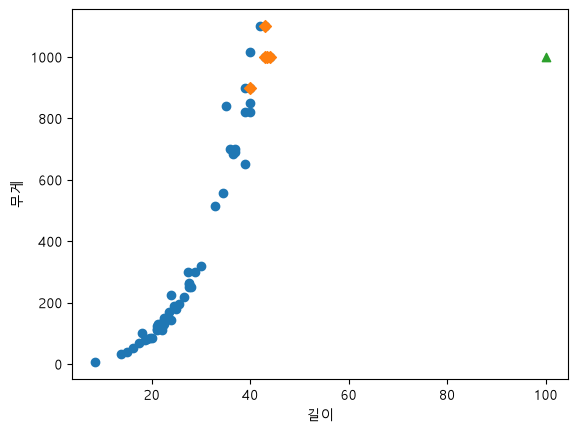

In [33]:
# 길이를 입력받아, 무게를 예측하시오. 
# 길이를 입력하세요.(예:27)
# 예측무게 : ?
i_data = input('길이를 입력하세요.(예:27)')   # 27-235, 33-586
i_data = float(i_data)   # 입력형태 float 
predict = knr.predict([[i_data]]) # 2차원배열[[]]
print('예측무게 : ',predict)
distances, indexes = knr.kneighbors([[i_data]])
indexes
# 산점도 그래프
plt.scatter(perch_length,perch_weight)
plt.scatter(train_data[indexes],train_label[indexes],marker='D')
plt.scatter(i_data,predict,marker='^')

plt.xlabel('길이')
plt.ylabel('무게')
plt.show()


In [ ]:
distances, indexes = knr.kneighbors([[i_data]])
indexes

array([[36, 38, 25, 29,  5]])

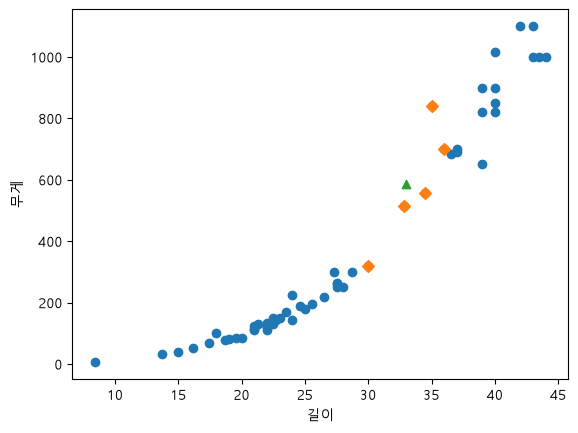

In [ ]:
# 산점도 그래프
plt.scatter(perch_length,perch_weight)
plt.scatter(train_data[indexes],train_label[indexes],marker='D')
plt.scatter(i_data,predict,marker='^')

plt.xlabel('길이')
plt.ylabel('무게')
plt.show()